# Perbandingan Naive Bayes — Gaussian, Complement, Bernoulli (BISINDO)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings,os,time,json
from sklearn.naive_bayes import GaussianNB,ComplementNB,BernoulliNB
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.preprocessing import LabelEncoder,StandardScaler,MinMaxScaler,Binarizer
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore');plt.rcParams['figure.dpi']=120
OUTPUT_DIR=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\NaiveBayes\\outputNBComparison";os.makedirs(OUTPUT_DIR,exist_ok=True)

In [2]:
data=np.load(r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\dataset_bisindo_landmarks.npz",allow_pickle=True)
X=np.nan_to_num(data['X'].astype(np.float32))
le=__import__('sklearn.preprocessing',fromlist=['LabelEncoder']).LabelEncoder()
y=le.fit_transform(data['labels'])
class_names=le.classes_
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
sc=StandardScaler();X_tr=sc.fit_transform(X_train);X_te=sc.transform(X_test)
mm=MinMaxScaler();X_tr_mm=mm.fit_transform(X_train);X_te_mm=mm.transform(X_test)
bn=Binarizer(threshold=0.0);X_tr_bin=bn.fit_transform(X_tr);X_te_bin=bn.transform(X_te)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [3]:
nb_configs=[
    ('Gaussian NB', GaussianNB(var_smoothing=1e-9), X_tr, X_te,
     Pipeline([('sc',StandardScaler()),('nb',GaussianNB(var_smoothing=1e-9))])),
    ('Complement NB', ComplementNB(alpha=1.0), X_tr_mm, X_te_mm,
     Pipeline([('mm',MinMaxScaler()),('nb',ComplementNB(alpha=1.0))])),
    ('Bernoulli NB', BernoulliNB(alpha=1.0), X_tr_bin, X_te_bin,
     Pipeline([('sc',StandardScaler()),('bn',Binarizer(threshold=0.0)),('nb',BernoulliNB(alpha=1.0))])),
]
results=[]
for name,model,Xtr,Xte,pipe in nb_configs:
    t0=time.time();model.fit(Xtr,y_train);tt=time.time()-t0
    t0=time.time();yp=model.predict(Xte);pt=time.time()-t0
    cvs=cross_val_score(pipe,X,y,cv=cv,scoring='f1_weighted',n_jobs=-1)
    results.append({'name':name,'accuracy':accuracy_score(y_test,yp),
        'precision':precision_score(y_test,yp,average='weighted',zero_division=0),
        'recall':recall_score(y_test,yp,average='weighted',zero_division=0),
        'f1_score':f1_score(y_test,yp,average='weighted',zero_division=0),
        'cv_f1_mean':cvs.mean(),'cv_f1_std':cvs.std(),'train_time':tt,'pred_time':pt,'y_pred':yp})
    print(f'{name}: Acc={results[-1]["accuracy"]:.4f} F1={results[-1]["f1_score"]:.4f}')

Gaussian NB: Acc=0.4573 F1=0.4004
Complement NB: Acc=0.3711 F1=0.3036
Bernoulli NB: Acc=0.4630 F1=0.4264


In [4]:
df=pd.DataFrame([{k:v for k,v in r.items() if k!='y_pred'} for r in results])
display(df[['name','accuracy','precision','recall','f1_score','cv_f1_mean','cv_f1_std']].style
    .format(precision=4).highlight_max(subset=['accuracy','f1_score'],color='#b8f0b8')
    .set_caption('Perbandingan Naive Bayes Variants'))

,name,accuracy,precision,recall,f1_score,cv_f1_mean,cv_f1_std
0,Gaussian NB,0.4573,0.4567,0.4573,0.4004,0.3545,0.0242
1,Complement NB,0.3711,0.3667,0.3711,0.3036,0.3054,0.0136
2,Bernoulli NB,0.4630,0.4698,0.4630,0.4264,0.4149,0.0015


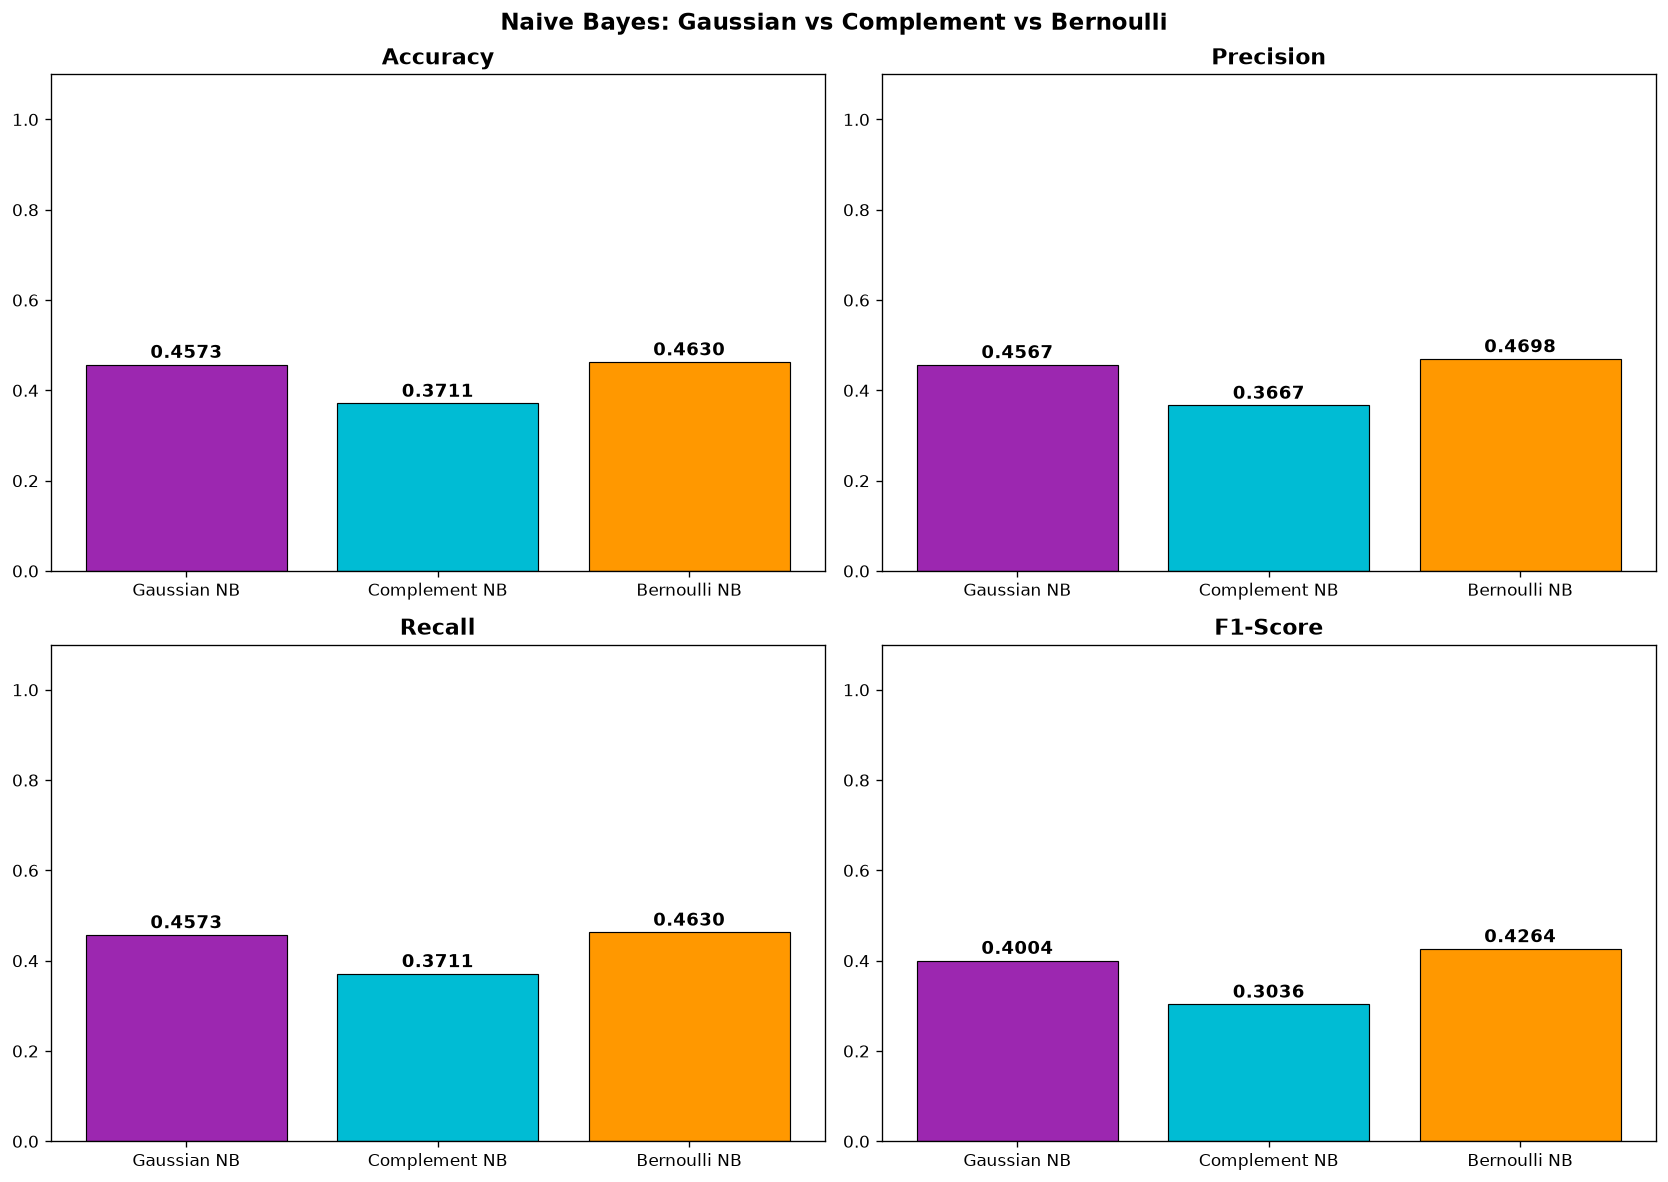

In [5]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
for ax,metric,label in zip(axes.flatten(),
    ['accuracy','precision','recall','f1_score'],['Accuracy','Precision','Recall','F1-Score']):
    vals=[r[metric] for r in results];names=[r['name'] for r in results]
    bars=ax.bar(names,vals,color=['#9C27B0','#00BCD4','#FF9800'],edgecolor='black',lw=0.7)
    ax.set_ylim(0,1.1);ax.set_title(label,fontsize=13,fontweight='bold')
    for b,v in zip(bars,vals): ax.text(b.get_x()+b.get_width()/2,b.get_height()+0.005,f'{v:.4f}',ha='center',va='bottom',fontsize=11,fontweight='bold')
plt.suptitle('Naive Bayes: Gaussian vs Complement vs Bernoulli',fontsize=14,fontweight='bold')
plt.tight_layout();plt.savefig(os.path.join(OUTPUT_DIR,'nb_comparison.png'),dpi=150,bbox_inches='tight');plt.show()

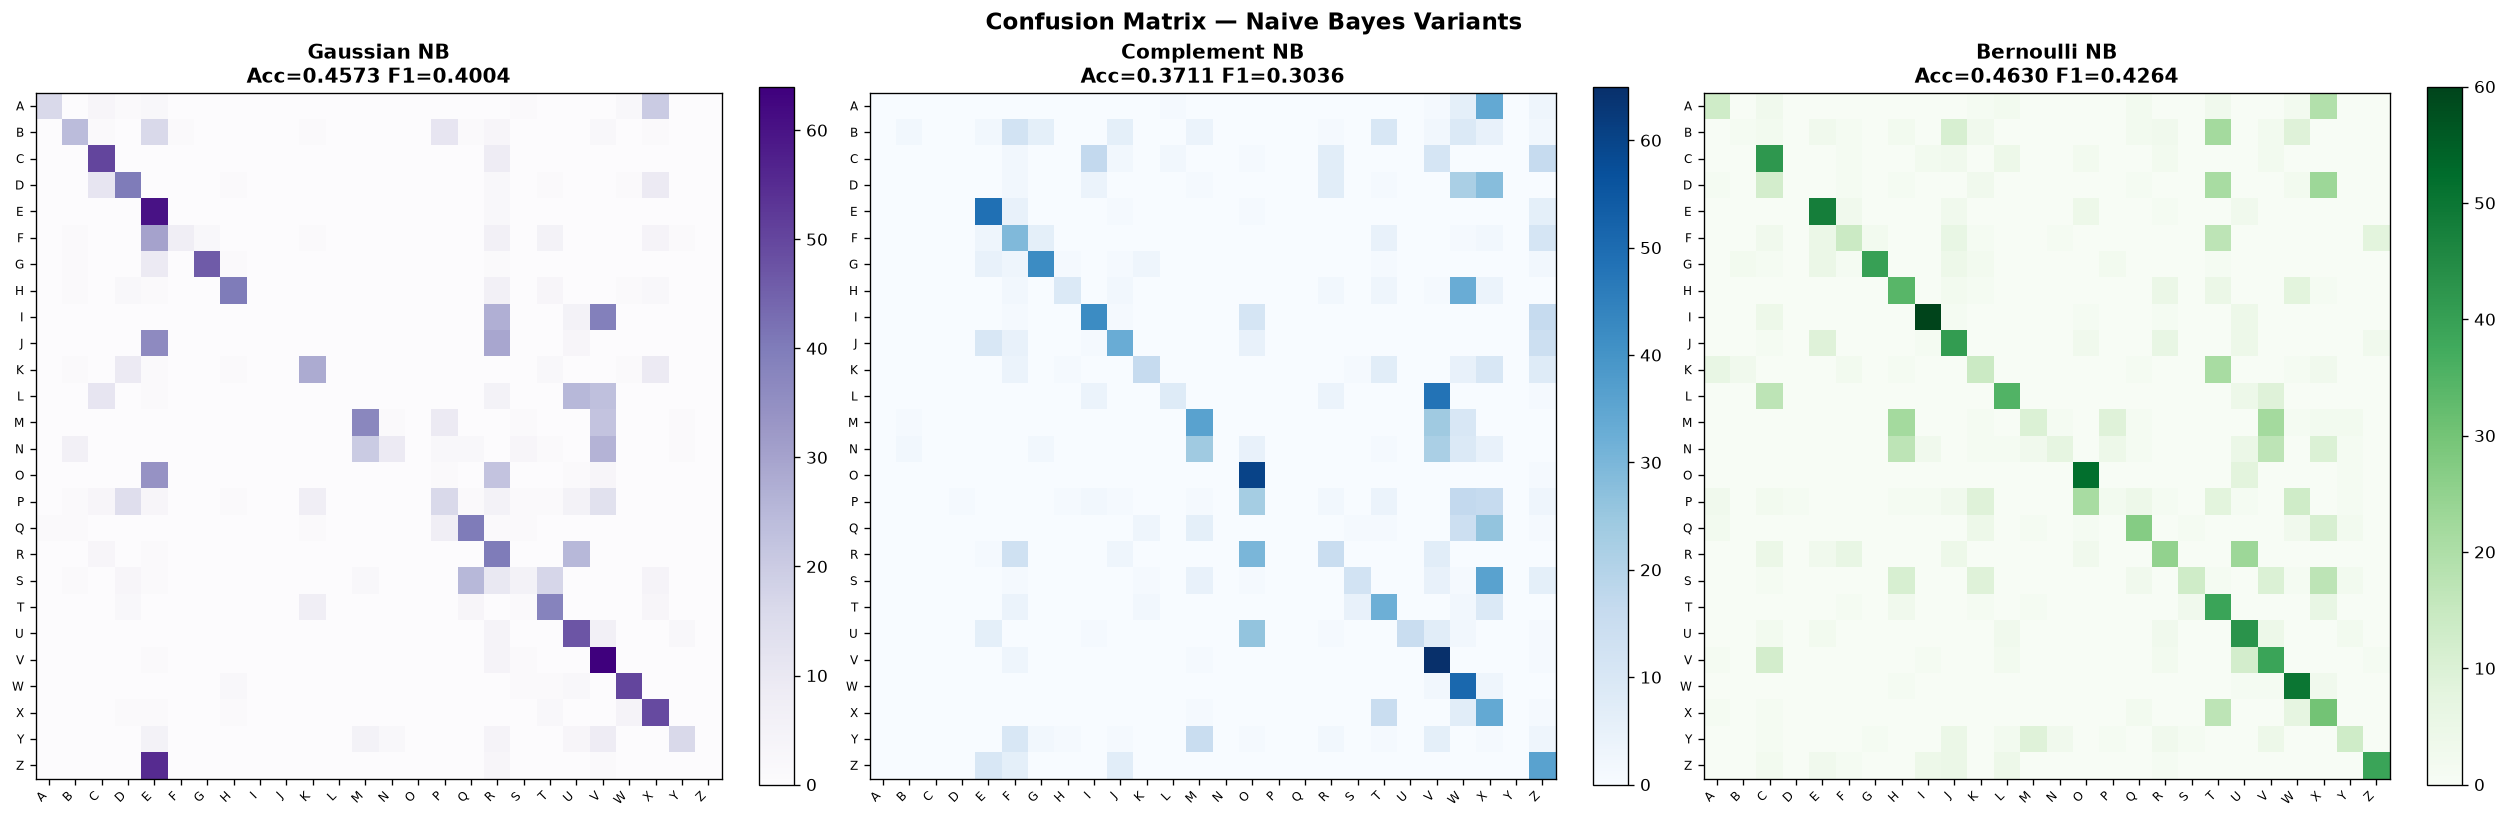

In [6]:
fig,axes=plt.subplots(1,3,figsize=(21,7))
for ax,r,cmap in zip(axes,results,['Purples','Blues','Greens']):
    cm=confusion_matrix(y_test,r['y_pred'])
    im=ax.imshow(cm,cmap=cmap,interpolation='nearest')
    plt.colorbar(im,ax=ax,fraction=0.046)
    ax.set_xticks(range(len(class_names)));ax.set_xticklabels(class_names,rotation=45,ha='right',fontsize=7)
    ax.set_yticks(range(len(class_names)));ax.set_yticklabels(class_names,fontsize=7)
    ax.set_title(f"{r['name']}\nAcc={r['accuracy']:.4f} F1={r['f1_score']:.4f}",fontweight='bold')
plt.suptitle('Confusion Matrix — Naive Bayes Variants',fontsize=14,fontweight='bold')
plt.tight_layout();plt.savefig(os.path.join(OUTPUT_DIR,'nb_cm_comparison.png'),dpi=150,bbox_inches='tight');plt.show()